# The Application of computational physics methods in finance -- Ali Khabazian // june 2024

1.1 Monte Carlo for finance 

1.1.1 Monte Carlo Simulation of a stock portfolio with python

Monte carlo method: computational simulation that rely on repeated random sampling to obtain results.
(we try to 'converge' to the exact answer)

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt 
from pandas_datareader import data as pdr


In [10]:
#import data
def get_data(stocks, start, end):
    stockData = pdr.get_data_yahoo(stocks, start, end)
    stockData = stockData['close']
    returns = stockData.pct_change()
    meanReturns = returns.mean()
    covmatrix = returns.cov()
    return meanReturns, covmatrix

stocklist = ['CBA', 'BHP', 'TLS', 'NAB', 'WBC', 'STO']
stocks = [stock + '.AX' for stock in stocklist]
endDate = dt.datetime.now()          
startDate = endDate - dt.timedelta(days=300)

meanReturns, covmatrix = get_data(stocks, startDate, endDate)
print(meanReturns)

AttributeError: 'NoneType' object has no attribute 'group'

In [11]:
import datetime as dt
import yfinance as yf

def get_data_yfinance(stocks, start, end):
    stockData = yf.download(stocks, start=start, end=end)
    stockData = stockData['Close']
    returns = stockData.pct_change()
    meanReturns = returns.mean()
    covmatrix = returns.cov()
    return meanReturns, covmatrix

stocklist = ['CBA', 'BHP', 'TLS', 'NAB', 'WBC', 'STO']
stocks = [stock + '.AX' for stock in stocklist]
endDate = dt.datetime.now()          
startDate = endDate - dt.timedelta(days=300)

meanReturns, covmatrix = get_data_yfinance(stocks, startDate, endDate)

if meanReturns is not None and covmatrix is not None:
    print("Mean Returns:\n", meanReturns)
    print("Covariance Matrix:\n", covmatrix)
else:
    print("Failed to retrieve data.")


[*********************100%%**********************]  6 of 6 completed

Mean Returns:
 Ticker
BHP.AX   -0.000012
CBA.AX    0.001192
NAB.AX    0.001248
STO.AX    0.000086
TLS.AX   -0.000406
WBC.AX    0.001238
dtype: float64
Covariance Matrix:
 Ticker    BHP.AX    CBA.AX    NAB.AX    STO.AX    TLS.AX    WBC.AX
Ticker                                                            
BHP.AX  0.000149  0.000045  0.000027  0.000044  0.000016  0.000034
CBA.AX  0.000045  0.000086  0.000063  0.000015  0.000029  0.000075
NAB.AX  0.000027  0.000063  0.000088  0.000010  0.000023  0.000075
STO.AX  0.000044  0.000015  0.000010  0.000186  0.000014  0.000010
TLS.AX  0.000016  0.000029  0.000023  0.000014  0.000075  0.000025
WBC.AX  0.000034  0.000075  0.000075  0.000010  0.000025  0.000124


In [15]:
weights = np.random.random(len(meanReturns))
weights /= np.sum(weights)

print(weights)

[0.04918056 0.10084122 0.28498542 0.03309698 0.03325487 0.49864094]


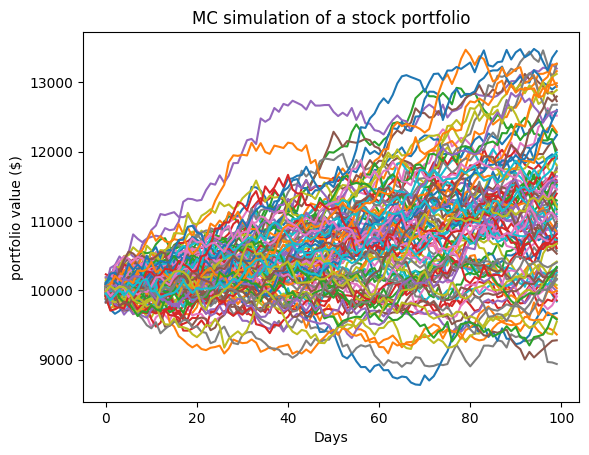

In [17]:
#monte carlo method
#number of simulations
mc_sims = 100
T = 100 #timeframe in days

meanM = np.full(shape=(T, len(weights)), fill_value=meanReturns)
meanM = meanM.T

portfolio_sims = np.full(shape=(T, mc_sims), fill_value=0.0)

initialportfolio = 10000


for m in range(0, mc_sims):
    #mc loops
    Z = np.random.normal(size=(T, len(weights)))
    L = np.linalg.cholesky(covmatrix)
    dailyReturns = meanM + np.inner(L, Z)
    portfolio_sims[:,m] = np.cumprod(np.inner(weights, dailyReturns.T)+1)*initialportfolio

plt.plot(portfolio_sims)
plt.ylabel('portfolio value ($)')
plt.xlabel('Days')
plt.title('MC simulation of a stock portfolio')
plt.show()

1.1.2 Value at Risk (VaR) and Conditional Value at Risk (CVaR) with monte carlo

In [35]:
def mcVaR(returns, alpha=5):
    """"" Input: pandas series of returns
          output: percentiles on return distribution to a given confidence level alpha
    """""
    if isinstance(returns, pd.Series):
        return np.percentile(returns, alpha)
    else:
        raise TypeError("Expected a pandas data series")
    

def mcCVaR(returns, alpha=5):
    """"" Input: pandas series of returns
          output: CVaR or Expected shortfall to a given confidence level alpha
    """""
    if isinstance(returns, pd.Series):
        belowVaR = returns <= mcVaR(returns, alpha=alpha)
        return returns[belowVaR].mean()
    else:
        raise TypeError("Expected a pandas data series")
    
portResults = pd.Series(portfolio_sims[-1,:])

VaR = initialportfolio - mcVaR(portResults, alpha=5)
CVaR = initialportfolio - mcCVaR(portResults, alpha=5)

print('VaR ${}'.format(round(VaR,2)))
print('CVaR ${}'.format(round(CVaR,2)))

VaR $403.89
CVaR $657.44


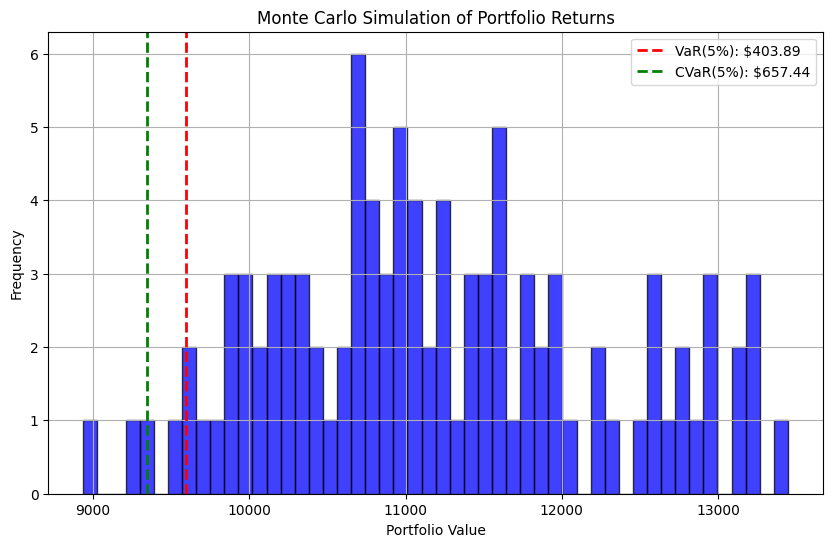

: 

In [38]:
plt.figure(figsize=(10, 6))
plt.hist(portResults, bins=50, alpha=0.75, color='blue', edgecolor='black')
plt.axvline(x=mcVaR(portResults, alpha=5), color='r', linestyle='--', linewidth=2, label=f'VaR(5%): ${round(VaR, 2)}')
plt.axvline(x=mcCVaR(portResults, alpha=5), color='g', linestyle='--', linewidth=2, label=f'CVaR(5%): ${round(CVaR, 2)}')
plt.title('Monte Carlo Simulation of Portfolio Returns')
plt.xlabel('Portfolio Value')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()

1.1.3 Monte Carlo Simulation for Option Pricing - basic ideas

In [1]:
import math
import numpy as np
import pandas as pd
import datetime
import scipy.stats as stats
import matplotlib.pyplot as plt
from pandas_datareader import data as pdr

In [59]:
#initial derivative parameters

S = 101.15     #stock price
K = 98.01      #strike price
vol = 0.0991   #volatility (%)
r = 0.01       #risk-free rate (%)
N = 10         #number of time steps
M = 1000       #number of simulations

market_value = 3.69    #market price of option
T = ((datetime.date(2022,3,17) - datetime.date(2022,1,19)).days+1) /365 #time in year
print(T)

0.1589041095890411


Slow solution - steps

In [61]:
#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
lnS = np.log(S)

#standard error placehokders
sum_CT = 0
sum_CT2 = 0

#Monte Carlo method
for i in range(M):
    lnSt = lnS
    for j in range(N):
        lnSt = lnSt + nudt + volsdt*np.random.normal()

    ST = np.exp(lnSt)
    CT = max(0, ST - K)
    sum_CT = sum_CT+ CT
    sum_CT2 = sum_CT2 + CT*CT

#compute expectation and SE
C0 = np.exp(-r*T)*sum_CT/M
sigma = np.sqrt( (sum_CT2 - sum_CT*sum_CT/M)*np.exp(-2*r*T) / (M-1) )
SE = sigma / np.sqrt(M)

print("call value is ${0} with Se +/- {1}".format(np.round(C0,2),np.round(SE,2)))

call value is $3.7 with Se +/- 0.11


Fast solution - Vectorized

In [63]:
#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
lnS = np.log(S)

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_lnSt = nudt + volsdt*Z
lnSt = lnS + np.cumsum(delta_lnSt, axis=0)
lnSt = np.concatenate( (np.full(shape=(1,M), fill_value=lnS), lnSt ))

#compute expectation and SE
ST = np.exp(lnSt)
CT = np.maximum(0, ST - K)
C0 = np.exp(-r*T)*np.sum(CT[-1])/M

sigma = np.sqrt( np.sum( (CT[-1] - C0)**2) / (M-1))
SE = sigma / np.sqrt(M)

print("call value is ${0} with SE +/- {1}".format(np.round(C0,2),np.round(SE,2)))

call value is $3.71 with SE +/- 0.11


Visualisation of Convergence

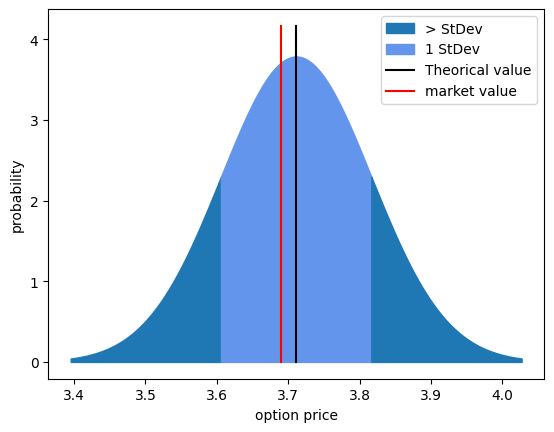

In [64]:
x1 = np.linspace(C0-3*SE, C0-1*SE, 100)
x2 = np.linspace(C0-1*SE, C0+1*SE, 100)
x3 = np.linspace(C0+1*SE, C0+3*SE, 100)

s1 = stats.norm.pdf(x1, C0, SE)
s2 = stats.norm.pdf(x2, C0, SE)
s3 = stats.norm.pdf(x3, C0, SE)

plt.fill_between(x1, s1, color='tab:blue', label='> StDev')
plt.fill_between(x2, s2, color='cornflowerblue', label='1 StDev')
plt.fill_between(x3, s3, color='tab:blue')

plt.plot([C0,C0],[0, max(s2)*1.1], 'k',
         label='Theorical value')
plt.plot([market_value,market_value],[0, max(s2)*1.1], 'r',
         label='market value')

plt.ylabel('probability')
plt.xlabel('option price')
plt.legend()
plt.show()

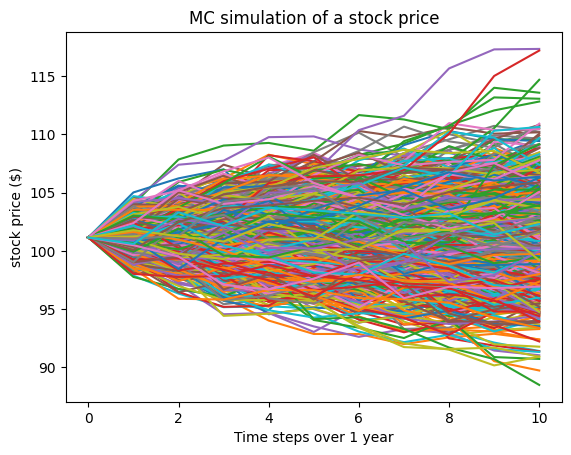

: 

In [65]:
plt.plot(ST)
plt.ylabel('stock price ($)')
plt.xlabel('Time steps over 1 year')
plt.title('MC simulation of a stock price')
plt.show()

1.1.4 Monte Carlo Variance Reduction with Antithetic Variates - Option Pricing Accuracy

In [1]:
 #import dependencies
import math
import numpy as np
import pandas as pd
import datetime
import scipy.stats as stats
import matplotlib.pyplot as plt

In [2]:
#initial derivative parameters

S = 101.15     #stock price
K = 98.01      #strike price
vol = 0.0991   #volatility (%)
r = 0.015      #risk-free rate (%)
N = 10         #number of time steps
M = 1000       #number of simulations

market_value = 3.86    #market price of option
T = ((datetime.date(2022,3,17) - datetime.date(2022,1,17)).days+1) /365 #time in year
print(T)

0.1643835616438356


Slow solution - steps

In [7]:
#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
lnS = np.log(S)

#standard error placehokders
sum_CT = 0
sum_CT2 = 0

#Monte Carlo method
for i in range(M):
    lnSt1 = lnS
    lnSt2 = lnS
    for j in range(N):
        #perfectly negatively correlated assets
        epsilon = np.random.normal()
        lnSt1 = lnSt1 + nudt + volsdt*epsilon
        lnSt2 = lnSt2 + nudt - volsdt*epsilon


    ST1 = np.exp(lnSt1)
    ST2 = np.exp(lnSt2)

    CT = 0.5 * (max(0, ST1 - K) + max(0, ST2 - K) )
    sum_CT = sum_CT+ CT
    sum_CT2 = sum_CT2 + CT*CT

#compute expectation and SE
C0 = np.exp(-r*T)*sum_CT/M
sigma = np.sqrt( (sum_CT2 - sum_CT*sum_CT/M)*np.exp(-2*r*T) / (M-1) )
SE = sigma / np.sqrt(M)

print("call value is ${0} with Se +/- {1}".format(np.round(C0,2),np.round(SE,2)))

call value is $3.81 with Se +/- 0.03


Fast solution - Vectorized

In [27]:
#precompute constants
N = 1
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
lnS = np.log(S)

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_lnSt1 = nudt + volsdt*Z
delta_lnSt2 = nudt - volsdt*Z

lnSt1 = lnS + np.cumsum(delta_lnSt1, axis=0)
lnSt2 = lnS + np.cumsum(delta_lnSt2, axis=0)


#compute expectation and SE
ST1 = np.exp(lnSt1)
ST2 = np.exp(lnSt2)
CT = 0.5 * ( np.maximum(0, ST1[-1] - K) + np.maximum(0,ST2[-1] - K) )
C0 = np.exp(-r*T)*np.sum(CT)/M

sigma = np.sqrt( np.sum( (CT - C0)**2) / (M-1))
SE = sigma / np.sqrt(M)

print("call value is ${0} with SE +/- {1}".format(np.round(C0,2),np.round(SE,2)))

call value is $3.87 with SE +/- 0.03


Compare without Antithetic Variate

In [40]:
#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
lnS = np.log(S)

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_lnSt = nudt + volsdt*Z
lnSt = lnS + np.cumsum(delta_lnSt, axis=0)
lnSt = np.concatenate( (np.full(shape=(1,M), fill_value=lnS), lnSt ))

#compute expectation and SE
ST = np.exp(lnSt)
CT = np.maximum(0, ST - K)
C0w = np.exp(-r*T)*np.sum(CT[-1])/M

sigma = np.sqrt( np.sum( (CT[-1] - C0)**2) / (M-1))
SEw = sigma / np.sqrt(M)

print("call value is ${0} with SE +/- {1}".format(np.round(C0,2),np.round(SE,2)))

call value is $3.86 with SE +/- 0.11


Visualisation of convergence

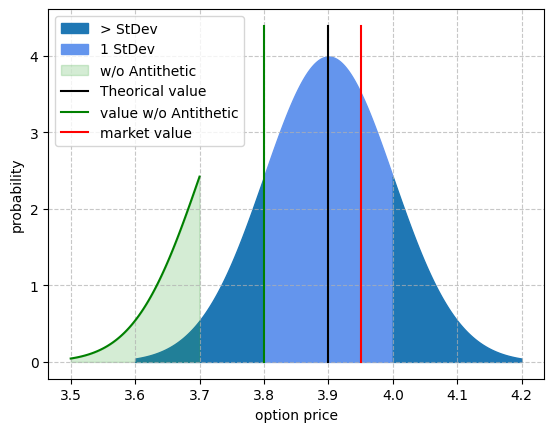

: 

In [51]:
x1 = np.linspace(C0-3*SE, C0-1*SE, 100)
x2 = np.linspace(C0-1*SE, C0+1*SE, 100)
x3 = np.linspace(C0+1*SE, C0+3*SE, 100)
xw = np.linspace(C0w-3*SEw, C0w-1*SEw, 100)

s1 = stats.norm.pdf(x1, C0, SE)
s2 = stats.norm.pdf(x2, C0, SE)
s3 = stats.norm.pdf(x3, C0, SE)
sw = stats.norm.pdf(xw, C0w, SEw)

plt.fill_between(x1, s1, color='tab:blue', label='> StDev')
plt.fill_between(x2, s2, color='cornflowerblue', label='1 StDev')
plt.fill_between(x3, s3, color='tab:blue')
plt.plot(xw, sw, 'g-')
plt.fill_between(xw, sw, alpha=0.2, color='tab:green', label='w/o Antithetic')

plt.plot([C0,C0],[0, max(s2)*1.1], 'k',
         label='Theorical value')
plt.plot([C0w,C0w],[0, max(s2)*1.1], color=(0, 0.5, 0) ,
         label='value w/o Antithetic')
plt.plot([market_value,market_value],[0, max(s2)*1.1], 'r',
         label='market value')

plt.ylabel('probability')
plt.xlabel('option price')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

1.1.5 Monte Carlo Variance Reduction with Control Variates - Option Pricing Accuracy

In [1]:
 #import dependencies
import math
import numpy as np
import pandas as pd
import datetime
import scipy.stats as stats
import matplotlib.pyplot as plt
from py_vollib.black_scholes.implied_volatility import implied_volatility as iv
from py_vollib.black_scholes import black_scholes as bs
from py_vollib.black_scholes.greeks.analytical import vega, delta

In [2]:
#initial derivative parameters

S = 101.15     #stock price
K = 98.01      #strike price
vol = 0.0991   #volatility (%)
r = 0.015      #risk-free rate (%)
N = 10         #number of time steps
M = 1000       #number of simulations

market_value = 3.86    #market price of option
T = ((datetime.date(2022,3,17) - datetime.date(2022,1,17)).days+1) /365 #time in year
print(T)

0.1643835616438356


Slow solution - steps

In [5]:
#precompute constants
N = 10
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
erdt = np.exp(r*dt)

beta1 = -1

#standard error placehokders
sum_CT = 0
sum_CT2 = 0

#Monte Carlo method
for i in range(M):
    St = S
    cv = 0
    for j in range(N):
        #perfectly negatively correlated assets
        epsilon = np.random.normal()
        deltaSt = delta('c', St, K, T-j*dt, r, vol)
        Stn = St*np.exp( nudt + volsdt*epsilon)
        cv = cv + deltaSt*(Stn - St*erdt)
        St = Stn

    CT = max(0, St - K) + beta1*cv
    sum_CT = sum_CT+ CT
    sum_CT2 = sum_CT2 + CT*CT

#compute expectation and SE
C0 = np.exp(-r*T)*sum_CT/M
sigma = np.sqrt( (sum_CT2 - sum_CT*sum_CT/M)*np.exp(-2*r*T) / (M-1) )
SE = sigma / np.sqrt(M)

print("call value is ${0} with Se +/- {1}".format(np.round(C0,2),np.round(SE,2)))

call value is $3.82 with Se +/- 0.01


Fast solution - Vectorized

In [6]:
def delta_calc(r, S, K, T, sigma, type="c"):
    "calculate delta of an option"
    d1 = (np.log(S/K)+ (r+sigma**2/2)*T)/(sigma*np.sqrt(T))
    try:
        if type == "c":
            delta_calc = stats.norm.cdf(d1, 0, 1)
        elif type == "p":
            delta_calc = -stats.norm.cdf(-d1, 0, 1)
        return delta_calc
    except:
        print("please confirm option type, either 'c' for call or 'p) for put!")

In [12]:
#precompute constants
N = 1
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)

erdt = np.exp(r*dt)
cv = 0
beta1 = -1

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_St = nudt + volsdt*Z
ST = S*np.cumprod(np.exp(delta_St), axis=0)
ST = np.concatenate( (np.full(shape=(1, M), fill_value=S), ST))
deltaSt = delta_calc(r, ST[:-1].T, K, np.linspace(T,0,N), vol, "c").T
cv = np.cumsum(deltaSt*(ST[1:]-ST[:-1]*erdt), axis=0)

CT = np.maximum(0, ST[-1] - K) + beta1*cv[-1]
#CT = np.maximum(0, ST[-1] - K)
C0 = np.exp(-r*T)*np.sum(CT)/ M

sigma = np.sqrt( np.sum( (np.exp(-r*T)*CT - C0)**2) / (M-1) )
sigma = np.std(np.exp(-r*T)*CT)
SE = sigma/np.sqrt(M)

print("call value is ${0} with SE +/- {1}".format(np.round(C0,2), np.round(SE,3)))

call value is $3.83 with SE +/- 0.03


Compare without Delta-based control variate

In [13]:
#precompute constants
N = 1
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_St = nudt + volsdt*Z
ST = S*np.cumprod( np.exp(delta_St), axis=0)

CTw = np.maximum(0, ST[-1] - K)
C0w = np.exp(-r*T)*np.sum(CTw)/ M

sigma = np.sqrt( np.sum( (np.exp(-r*T)*CTw - C0w)**2) / (M-1) )
SEw = sigma/np.sqrt(M)

print("call value is ${0} with SE +/- {1}".format(np.round(C0w,2), np.round(SEw,3)))

call value is $3.78 with SE +/- 0.108


Visualisation of convergence

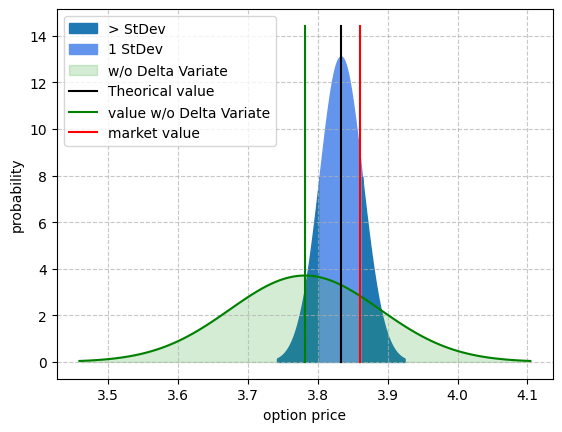

: 

In [15]:
x1 = np.linspace(C0-3*SE, C0-1*SE, 100)
x2 = np.linspace(C0-1*SE, C0+1*SE, 100)
x3 = np.linspace(C0+1*SE, C0+3*SE, 100)
xw = np.linspace(C0w-3*SEw, C0w+3*SEw, 100)

s1 = stats.norm.pdf(x1, C0, SE)
s2 = stats.norm.pdf(x2, C0, SE)
s3 = stats.norm.pdf(x3, C0, SE)
sw = stats.norm.pdf(xw, C0w, SEw)

plt.fill_between(x1, s1, color='tab:blue', label='> StDev')
plt.fill_between(x2, s2, color='cornflowerblue', label='1 StDev')
plt.fill_between(x3, s3, color='tab:blue')
plt.plot(xw, sw, 'g-')
plt.fill_between(xw, sw, alpha=0.2, color='tab:green', label='w/o Delta Variate')

plt.plot([C0,C0],[0, max(s2)*1.1], 'k',
         label='Theorical value')
plt.plot([C0w,C0w],[0, max(s2)*1.1], color=(0, 0.5, 0) ,
         label='value w/o Delta Variate')
plt.plot([market_value,market_value],[0, max(s2)*1.1], 'r',
         label='market value')

plt.ylabel('probability')
plt.xlabel('option price')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

1.1.6 Why Gamma matters?

In [48]:
import time
import math
import datetime
import numpy as np
import pandas as pd
import scipy.stats as stats
from py_vollib.black_scholes import black_scholes as bs

In [49]:
#initial derivative parameters

S = 101.15     #stock price
K = 98.01      #strike price
vol = 0.0991   #volatility (%)
r = 0.015      #risk-free rate (%)
N = 20         #number of time steps
M = 1000       #number of simulations

market_value = 3.86    #market price of option
T = ((datetime.date(2022,3,17) - datetime.date(2022,1,17)).days+1) /365 #time in year
print(T)

0.1643835616438356


Sample Estimate - no variance reduction methods

In [50]:
start_time = time.time()

#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
lnS = np.log(S)

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_lnSt = nudt + volsdt*Z
lnSt = lnS + np.cumsum(delta_lnSt, axis=0)
lnSt = np.concatenate( (np.full(shape=(1,M), fill_value=lnS), lnSt ))

#compute expectation and SE
ST = np.exp(lnSt)
CT = np.maximum(0, ST - K)
C0_se = np.exp(-r*T)*np.sum(CT[-1])/M

sigma = np.sqrt( np.sum( np.exp((-r*T)*CT[-1] - C0_se)**2) / (M-1))
SE_se = sigma / np.sqrt(M)

mc_time_se = time.time() - start_time



print("sample estimate: call value is ${0} with Se +/- {1}".format(np.round(C0_se,2),np.round(SE_se,3)))
print("computation time is:", round(mc_time_se,4))

sample estimate: call value is $3.74 with Se +/- 0.001
computation time is: 0.0034


Implementation of Antithetic variate

In [51]:
start_time = time.time()

#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
lnS = np.log(S)

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_lnSt1 = nudt + volsdt*Z
delta_lnSt2 = nudt - volsdt*Z

lnSt1 = lnS + np.cumsum(delta_lnSt1, axis=0)
lnSt2 = lnS + np.cumsum(delta_lnSt2, axis=0)


#compute expectation and SE
ST1 = np.exp(lnSt1)
ST2 = np.exp(lnSt2)
CT = 0.5 * ( np.maximum(0, ST1[-1] - K) + np.maximum(0,ST2[-1] - K) )
C0_av = np.exp(-r*T)*np.sum(CT)/M

sigma = np.sqrt( np.sum( (np.exp(-r*T)*CT - C0_av)**2) / (M-1))
SE_av = sigma / np.sqrt(M)

mc_time_av = time.time() - start_time

print("call value is ${0} with SE +/- {1}".format(np.round(C0_av,2),np.round(SE_av,2)))
print("computation time is:", round(mc_time_av,4))

call value is $3.83 with SE +/- 0.03
computation time is: 0.002


In [52]:
def delta_calc(r, S, K, T, sigma, type="c"):
    "calculate delta of an option"
    d1 = (np.log(S/K)+ (r+sigma**2/2)*T)/(sigma*np.sqrt(T))
    try:
        if type == "c":
            delta_calc = stats.norm.cdf(d1, 0, 1)
        elif type == "p":
            delta_calc = -stats.norm.cdf(-d1, 0, 1)
        return delta_calc
    except:
        print("please confirm option type, either 'c' for call or 'p) for put!")

In [53]:
start_time = time.time()

#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)

erdt = np.exp(r*dt)
cv = 0
beta1 = -1

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_St = nudt + volsdt*Z
ST = S*np.cumprod(np.exp(delta_St), axis=0)
ST = np.concatenate( (np.full(shape=(1, M), fill_value=S), ST))
deltaSt = delta_calc(r, ST[:-1].T, K, np.linspace(T,0,N), vol, "c").T
cv = np.cumsum(deltaSt*(ST[1:]-ST[:-1]*erdt), axis=0)

CT = np.maximum(0, ST[-1] - K) + beta1*cv[-1]
#CT = np.maximum(0, ST[-1] - K)
C0_dv = np.exp(-r*T)*np.sum(CT)/ M

sigma = np.sqrt( np.sum( (np.exp(-r*T)*CT - C0_dv)**2) / (M-1) )
sigma = np.std(np.exp(-r*T)*CT)
SE_dv = sigma/np.sqrt(M)

mc_time_dv = time.time() - start_time

print("call value is ${0} with SE +/- {1}".format(np.round(C0_dv,2),np.round(SE_dv,3)))
print("computation time is:", round(mc_time_dv,4))

call value is $3.82 with SE +/- 0.008
computation time is: 0.0076


C:\Users\user\AppData\Local\Temp\ipykernel_3504\398042284.py:3: RuntimeWarning: divide by zero encountered in divide
  d1 = (np.log(S/K)+ (r+sigma**2/2)*T)/(sigma*np.sqrt(T))


Gamma Based control variate

In [54]:
def gamma_calc(r, S, K, T, sigma):
    "calculate delta of an option"
    d1 = (np.log(S/K)+ (r+sigma**2/2)*T)/(sigma*np.sqrt(T)) 
    try:
        gamma_calc = stats.norm.pdf(d1, 0, 1)/(S*sigma*np.sqrt(T))
        return gamma_calc
    except:
        print("please confirm option type, either 'c' for call or 'p' for put!" )

In [55]:
start_time = time.time()

#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
erdt = np.exp(r*dt)
ergamma = np.exp((2*r+vol**2)*dt) - 2*erdt + 1
beta2 = -0.5

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_St = nudt + volsdt*Z
ST = S*np.cumprod(np.exp(delta_St), axis=0)
ST = np.concatenate( (np.full(shape=(1, M), fill_value=S), ST))

gammaSt = gamma_calc(r, ST[:-1].T, K, np.linspace(T,dt,N), vol).T
cv2 = np.cumsum(gammaSt*((ST[1:]-ST[:-1])**2 - ergamma*ST[:-1]**2), axis=0)

CT = np.maximum(0, ST[-1] - K) + beta2*cv2[-1]
#CT = np.maximum(0, ST[-1] - K)
C0_gv = np.exp(-r*T)*np.sum(CT)/ M

sigma = np.sqrt( np.sum( (np.exp(-r*T)*CT - C0_gv)**2) / (M-1) )
sigma = np.std(np.exp(-r*T)*CT)
SE_gv = sigma/np.sqrt(M)

mc_time_gv = time.time() - start_time

print("call value is ${0} with SE +/- {1}".format(np.round(C0_gv,2),np.round(SE_gv,3)))
print("computation time is:", round(mc_time_gv,4))

call value is $3.64 with SE +/- 0.104
computation time is: 0.0061


Combined antithetic and delta variates

In [56]:
start_time = time.time()

#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
erdt = np.exp(r*dt)

beta1 = -1

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_St1 = nudt + volsdt*Z
delta_St2 = nudt - volsdt*Z
ST1 = S*np.cumprod(np.exp(delta_St1), axis=0)
ST2 = S*np.cumprod(np.exp(delta_St2), axis=0)
ST1 = np.concatenate( (np.full(shape=(1, M), fill_value=S), ST1))
ST2 = np.concatenate( (np.full(shape=(1, M), fill_value=S), ST2))

#calculate delta for both sets of underlying stock prices
deltaSt1 = delta_calc(r, ST1[:-1].T, K, np.linspace(T,dt,N), vol, "c").T
deltaSt2 = delta_calc(r, ST2[:-1].T, K, np.linspace(T,dt,N), vol, "c").T

#calculate two sets of delta control variates for negatively correlated assets
cv11 = np.cumsum(deltaSt1*(ST1[1:]-ST1[:-1]*erdt), axis=0)
cv12 = np.cumsum(deltaSt2*(ST2[1:]-ST2[:-1]*erdt), axis=0)

CT = 0.5* (  np.maximum(0, ST1[-1] - K) + beta1*cv11[-1]
           + np.maximum(0, ST2[-1] - K) + beta1*cv12[-1] )

#CT = np.maximum(0, ST[-1] - K)
C0_adv = np.exp(-r*T)*np.sum(CT)/ M

sigma = np.sqrt( np.sum( (np.exp(-r*T)*CT - C0_adv)**2) / (M-1) )
sigma = np.std(np.exp(-r*T)*CT)
SE_adv = sigma/np.sqrt(M)

mc_time_adv = time.time() - start_time

print("call value is ${0} with SE +/- {1}".format(np.round(C0_adv,2),np.round(SE_adv,3)))
print("computation time is:", round(mc_time_adv,4))


call value is $3.82 with SE +/- 0.006
computation time is: 0.0098


Combined antithetic, delta and gamma variates

In [57]:
start_time = time.time()

#precompute constants
dt = T/N
nudt = (r - 0.5*vol**2)*dt
volsdt = vol*np.sqrt(dt)
erdt = np.exp(r*dt)
ergamma = np.exp((2*r+vol**2)*dt) - 2*erdt + 1 

beta1 = -1
beta2 = -0.5

#monte carlo method
Z = np.random.normal(size=(N,M))
delta_St1 = nudt + volsdt*Z
delta_St2 = nudt - volsdt*Z
ST1 = S*np.cumprod(np.exp(delta_St1), axis=0)
ST2 = S*np.cumprod(np.exp(delta_St2), axis=0)
ST1 = np.concatenate( (np.full(shape=(1, M), fill_value=S), ST1))
ST2 = np.concatenate( (np.full(shape=(1, M), fill_value=S), ST2))

#calculate delta for both sets of underlying stock prices
deltaSt1 = delta_calc(r, ST1[:-1].T, K, np.linspace(T,dt,N), vol, "c").T
deltaSt2 = delta_calc(r, ST2[:-1].T, K, np.linspace(T,dt,N), vol, "c").T

#calculate gamma for both sets of underlying stoc prices
gammaSt1 = gamma_calc(r, ST1[:-1].T, K, np.linspace(T,dt,N), vol).T
gammaSt2 = gamma_calc(r, ST2[:-1].T, K, np.linspace(T,dt,N), vol).T

#calculate two sets of delta control variates for negatively correlated assets
cv11 = np.cumsum(deltaSt1*(ST1[1:]-ST1[:-1]*erdt), axis=0)
cv12 = np.cumsum(deltaSt2*(ST2[1:]-ST2[:-1]*erdt), axis=0)

#calculate two sets of gamma control variates for negatively correlated assets
cv21 = np.cumsum(gammaSt1*((ST1[1:] - ST1[:-1])**2 - ergamma*ST1[:-1]**2), axis=0)
cv22 = np.cumsum(gammaSt2*((ST2[1:] - ST2[:-1])**2 - ergamma*ST2[:-1]**2), axis=0)

CT = 0.5* (  np.maximum(0, ST1[-1] - K) + beta1*cv11[-1] + beta2*cv21[-1]
           + np.maximum(0, ST2[-1] - K) + beta1*cv12[-1] + beta2*cv22[-1])

#CT = np.maximum(0, ST[-1] - K)
C0_adgv = np.exp(-r*T)*np.sum(CT)/ M

sigma = np.sqrt( np.sum( (np.exp(-r*T)*CT - C0_adgv)**2) / (M-1) )
sigma = np.std(np.exp(-r*T)*CT)
SE_adgv = sigma/np.sqrt(M)

mc_time_adgv = time.time() - start_time

print("call value is ${0} with SE +/- {1}".format(np.round(C0_adgv,2),np.round(SE_adgv,3)))
print("computation time is:", round(mc_time_adgv,4))

call value is $3.82 with SE +/- 0.001
computation time is: 0.0083


Comparing Reduction Methods

Reviewing contract details

In [61]:
parameters = [K,round(T,2),S,vol,r,N,M,round(bs('c',S,K,T,r,vol),2), market_value]

parameters_rd = [round(parameters,2) for parameters in parameters]


data = {'contract terms': ['strike price', 'time to maturity', 'asset price', 'volatility', 
                           'riskfree rate' ,'number of time steps', 'number of simulations',
                           'standard european call price', 'market price'],
        'Parameters': parameters_rd}

#create pandas dataframe.
df = pd.DataFrame(data) #, index =['position1', 'position2', 'position3', 'position4'])

df


,contract terms,Parameters
0,strike price,98.01
1,time to maturity,0.16
2,asset price,101.15
3,volatility,0.10
4,riskfree rate,0.01
5,number of time steps,20.00
6,number of simulations,1000.00
7,standard european call price,3.82
8,market price,3.86


trade-off between error vs computation time (a comparison between mc variance reduction methods)

In [62]:
se_variates = [SE_se, SE_av, SE_dv, SE_gv, SE_adv, SE_adgv]
se_rd = [round(se,4) for se in se_variates]
se_red = [round(SE_se/se,2) for se in se_variates]

comp_time = [mc_time_se, mc_time_av, mc_time_dv, mc_time_gv, mc_time_adv, mc_time_adgv]
rel_time = [round(mc_time/mc_time_se,2) for mc_time in comp_time]

data = {'Standard Error (SE)': se_rd,
        'SE Reduction Multiple': se_red,
        'Relative Computation Time': rel_time}

# Creates pandas DataFrame.
df = pd.DataFrame(data, index =['Simple estimate', 'with antithetic variate',
'with delta-based control variate', 'with gamma-based control variate', 'with antithetic and delta variates', 'with all combined variates'])

df

,Standard Error (SE),SE Reduction Multiple,Relative Computation Time
Simple estimate,0.0007,1.00,1.00
with antithetic variate,0.0287,0.03,0.59
with delta-based control variate,0.0080,0.09,2.23
with gamma-based control variate,0.1038,0.01,1.79
with antithetic and delta variates,0.0059,0.13,2.87
with all combined variates,0.0014,0.55,2.44
